# DSCI 552 — Homework 5

**GitHub Username:** zl535992549-cell   
**USC ID:** 8768388438  

In [ ]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import cross_val_score, KFold, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

DATA = Path('../data') if Path('../data').exists() else Path('data')

## 1. (a)(b)

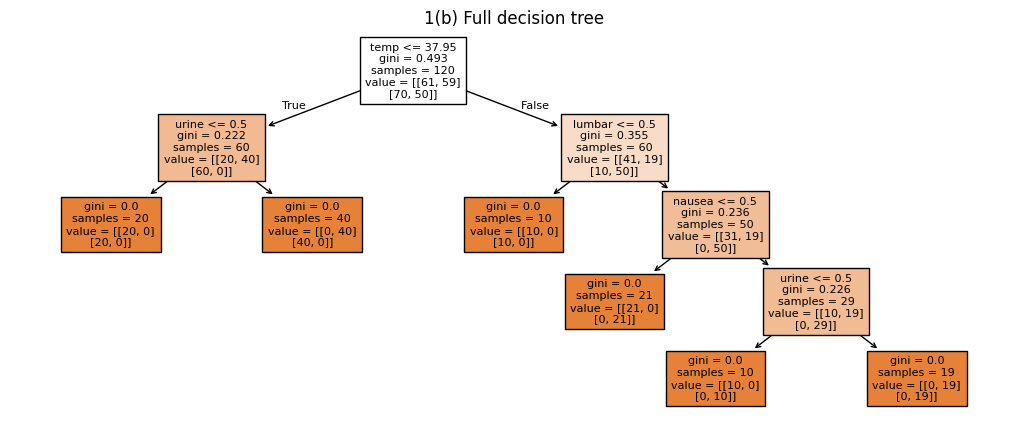

Full tree: 6 leaves; accuracy: 1.0


In [ ]:
cols = ['temp','nausea','lumbar','urine','micturition','burning','bladder','nephritis']
a = pd.read_csv(DATA/'acute_inflammations/diagnosis.data', sep=r'\s+',
                names=cols, encoding='utf-16', header=None)
a['temp'] = a['temp'].str.replace(',', '.').astype(float)
a[cols[1:]] = (a[cols[1:]] == 'yes').astype(int)
Xa, ya = a[cols[:6]], a[cols[6:]]
tree = DecisionTreeClassifier(random_state=42).fit(Xa, ya)
plt.figure(figsize=(13, 5))
plot_tree(tree, feature_names=Xa.columns, filled=True, fontsize=8)
plt.title('1(b) Full decision tree'); plt.show()
print('Full tree:', tree.get_n_leaves(), 'leaves; accuracy:', round(tree.score(Xa, ya), 3))

### 1(c)

In [ ]:
def rules(model):
    t = model.tree_
    def visit(node, path):
        if t.children_left[node] == -1:
            labels = [int(t.value[node, j].argmax()) for j in range(2)]
            print('IF', ' AND '.join(path) or 'True', 'THEN bladder, nephritis =', labels)
            return
        name, cut = Xa.columns[t.feature[node]], t.threshold[node]
        visit(t.children_left[node], path + [f'{name} <= {cut:.2f}'])
        visit(t.children_right[node], path + [f'{name} > {cut:.2f}'])
    visit(0, [])
rules(tree)

IF temp <= 37.95 AND urine <= 0.50 THEN bladder, nephritis = [0, 0]
IF temp <= 37.95 AND urine > 0.50 THEN bladder, nephritis = [1, 0]
IF temp > 37.95 AND lumbar <= 0.50 THEN bladder, nephritis = [0, 0]
IF temp > 37.95 AND lumbar > 0.50 AND nausea <= 0.50 THEN bladder, nephritis = [0, 1]
IF temp > 37.95 AND lumbar > 0.50 AND nausea > 0.50 AND urine <= 0.50 THEN bladder, nephritis = [0, 1]
IF temp > 37.95 AND lumbar > 0.50 AND nausea > 0.50 AND urine > 0.50 THEN bladder, nephritis = [1, 1]


### 1(d)

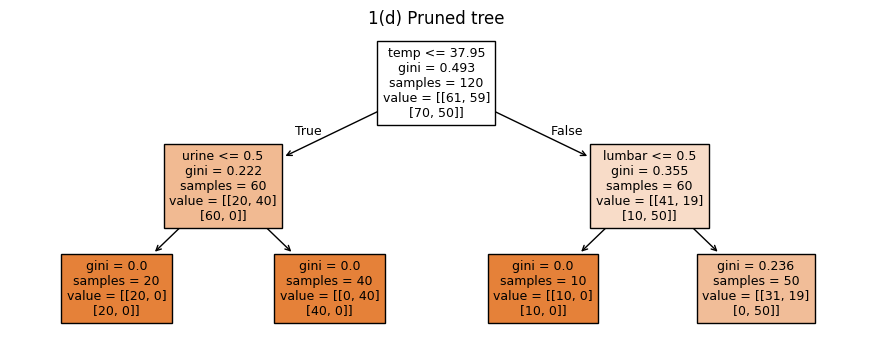

Alpha: 0.04908 | CV accuracy: 0.892 | Leaves: 4
IF temp <= 37.95 AND urine <= 0.50 THEN bladder, nephritis = [0, 0]
IF temp <= 37.95 AND urine > 0.50 THEN bladder, nephritis = [1, 0]
IF temp > 37.95 AND lumbar <= 0.50 THEN bladder, nephritis = [0, 0]
IF temp > 37.95 AND lumbar > 0.50 THEN bladder, nephritis = [0, 1]


In [ ]:
alphas = np.unique(tree.cost_complexity_pruning_path(Xa, ya).ccp_alphas)
cv = KFold(5, shuffle=True, random_state=42)
scores = [cross_val_score(DecisionTreeClassifier(ccp_alpha=x, random_state=42),
                          Xa, ya, cv=cv).mean() for x in alphas]
choices = [i for i, s in enumerate(scores) if s >= 0.85]
i = choices[-1] if choices else int(np.argmax(scores))
pruned = DecisionTreeClassifier(ccp_alpha=alphas[i], random_state=42).fit(Xa, ya)
plt.figure(figsize=(11, 4))
plot_tree(pruned, feature_names=Xa.columns, filled=True, fontsize=9)
plt.title('1(d) Pruned tree'); plt.show()
print('Alpha:', round(alphas[i], 5), '| CV accuracy:', round(scores[i], 3),
      '| Leaves:', pruned.get_n_leaves())
rules(pruned)

## 2. (a-b)

In [ ]:
names = re.findall(r'^@attribute\s+(\S+)',
                   (DATA/'communities_crime/communities.names').read_text(), re.M)
df = pd.read_csv(DATA/'communities_crime/communities.data', names=names,
                 header=None, na_values='?')
X = df.drop(columns=['state','county','community','communityname','fold','ViolentCrimesPerPop'])
y = df['ViolentCrimesPerPop']
Xtr, Xte, ytr, yte = X.iloc[:1495], X.iloc[1495:], y.iloc[:1495], y.iloc[1495:]
imp = SimpleImputer(strategy='median')
A = pd.DataFrame(imp.fit_transform(Xtr), columns=X.columns)
B = pd.DataFrame(imp.transform(Xte), columns=X.columns)
print('Train/test rows:', len(A), len(B), '| Features:', A.shape[1])

Train/test rows: 1495 499 | Features: 122


### 2(c)

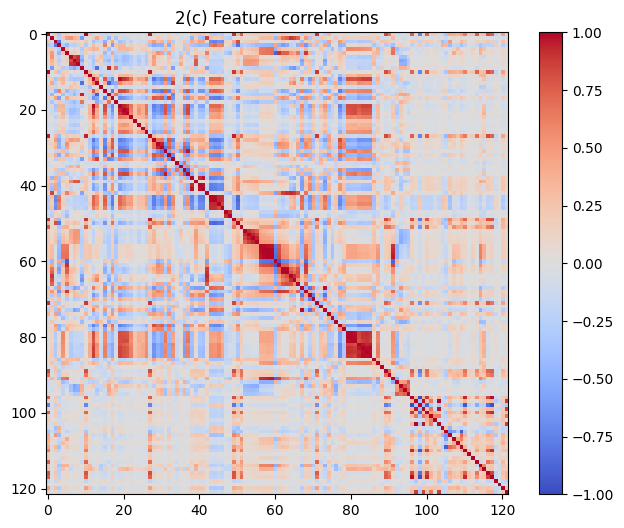

In [ ]:
plt.figure(figsize=(8, 6))
plt.imshow(A.corr(), cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(); plt.title('2(c) Feature correlations'); plt.show()

### 2(d)(e)

CV for each feature:
 population               2.241105
householdsize            0.355800
racepctblack             1.428885
racePctWhite             0.330213
racePctAsian             1.359100
racePctHisp              1.612091
agePct12t21              0.369083
agePct12t29              0.291315
agePct16t24              0.500310
agePct65up               0.412776
numbUrban                2.038461
pctUrban                 0.643318
medIncome                0.591978
pctWWage                 0.328614
pctWFarmSelf             0.701898
pctWInvInc               0.365335
pctWSocSec               0.360715
pctWPubAsst              0.706206
pctWRetire               0.345421
medFamInc                0.540670
perCapInc                0.558079
whitePerCap              0.519828
blackPerCap              0.599341
indianPerCap             0.818368
AsianPerCap              0.614866
OtherPerCap              0.673279
HispPerCap               0.484068
NumUnderPov              2.342443
PctPopUnderPov           0

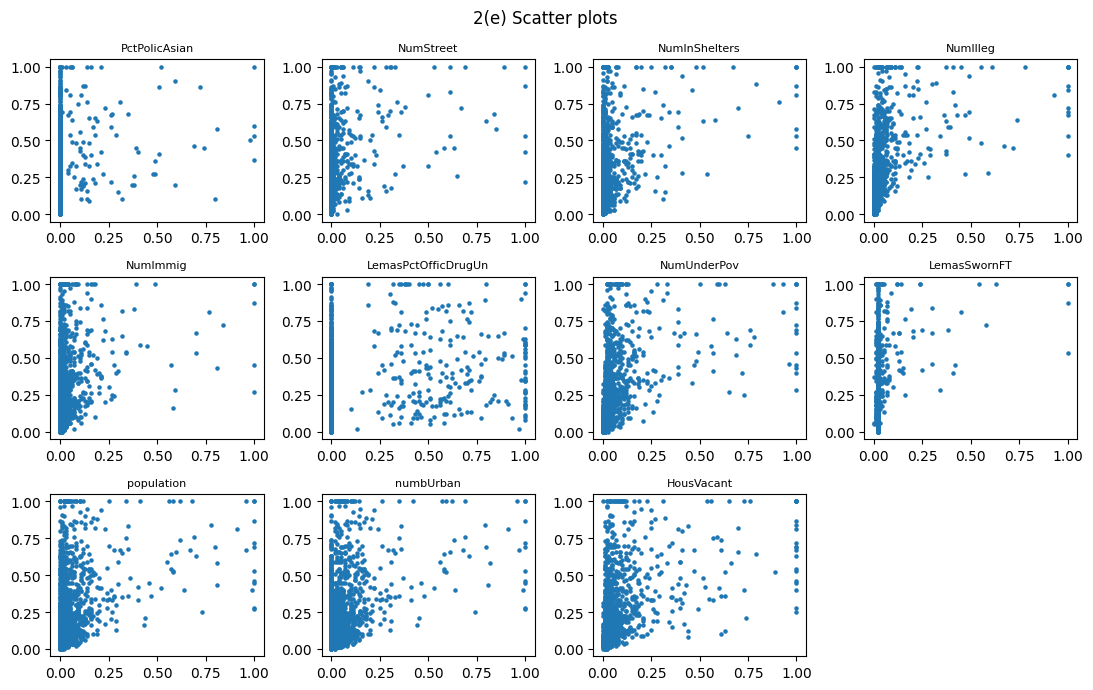

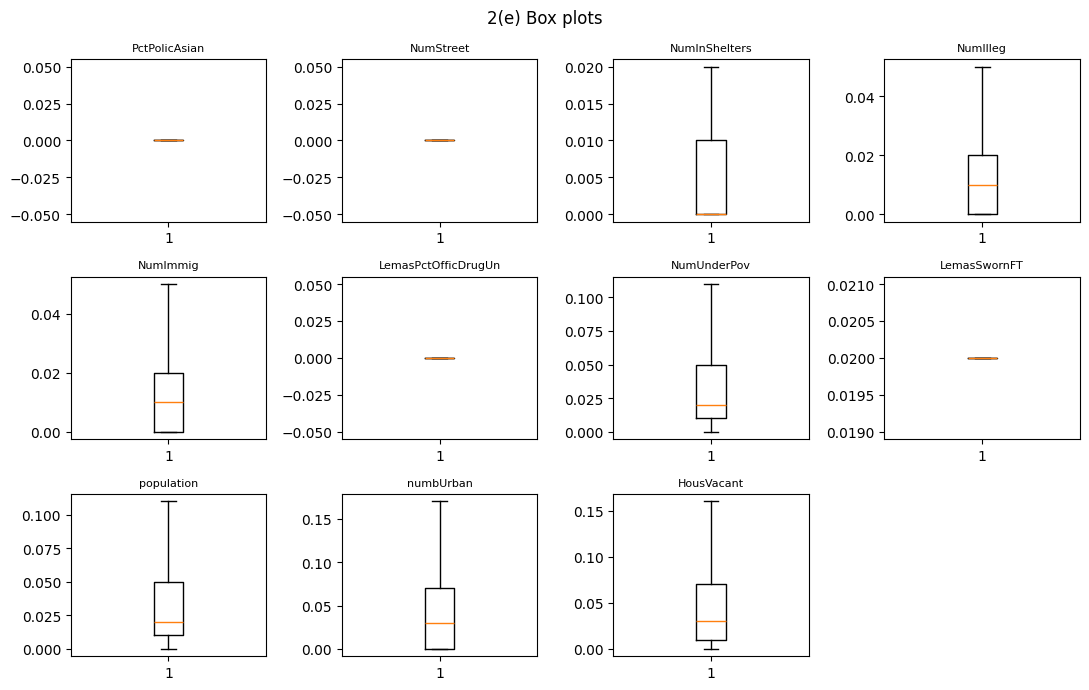

In [ ]:
cv_values = A.std(ddof=1) / A.mean().replace(0, np.nan)
top = cv_values.dropna().nlargest(int(np.sqrt(len(names))))
print('CV for each feature:\n', cv_values.to_string())
print('Top-CV features:', top.index.tolist())
for kind in ['scatter', 'box']:
    fig, axs = plt.subplots(3, 4, figsize=(11, 7))
    for ax, col in zip(axs.flat, top.index):
        if kind == 'scatter':
            ax.scatter(A[col], ytr, s=5)
        else:
            ax.boxplot(A[col], showfliers=False)
        ax.set_title(col, fontsize=8)
    for ax in list(axs.flat)[len(top):]: ax.axis('off')
    fig.suptitle('2(e) ' + kind.title() + ' plots')
    plt.tight_layout(); plt.show()

**2(e) Answer:** Scatter plots alone cannot establish statistical significance.

### 2(f–g-h)

In [ ]:
errors = {}
def test(name, model, train=A, test=B):
    model.fit(train, ytr)
    errors[name] = mean_squared_error(yte, model.predict(test))
    print(name, 'test MSE:', round(errors[name], 6))
    return model

ols = test('OLS', LinearRegression())
ridge = test('Ridge', RidgeCV(alphas=np.logspace(-4, 4, 30), cv=5))
print('Ridge lambda:', ridge.alpha_)
for label, scale in [('LASSO', False), ('LASSO scaled', True)]:
    steps = [StandardScaler()] if scale else []
    m = test(label, make_pipeline(*steps, LassoCV(cv=5, max_iter=15000,
                                                  alphas=60, random_state=42)))
    lasso = m[-1]
    print(label, 'lambda:', round(lasso.alpha_, 6))
    print('Selected variables:', A.columns[lasso.coef_ != 0].tolist())
print('Lower LASSO MSE:', min(['LASSO', 'LASSO scaled'], key=errors.get))

OLS test MSE: 0.017966


Ridge test MSE: 0.017502
Ridge lambda: 2.592943797404667
LASSO test MSE: 0.017607
LASSO lambda: 0.000132
Selected variables: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec5', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwn

LASSO scaled test MSE: 0.017671
LASSO scaled lambda: 0.000808
Selected variables: ['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec5', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn', 'PctSameCity85', 'Lem

### 2(i)

In [ ]:
pcr = GridSearchCV(make_pipeline(StandardScaler(), PCA(), LinearRegression()),
                   {'pca__n_components': [1, 2, 5, 10, 20, 40, 60, 80, 100, 122]},
                   scoring='neg_mean_squared_error', cv=5)
test('PCR', pcr)
print('Best number of PCs:', pcr.best_params_['pca__n_components'])

PCR test MSE: 0.018296
Best number of PCs: 100


### 2(j)

In [ ]:
xgb = GridSearchCV(XGBRegressor(n_estimators=200, learning_rate=0.05,
                  max_depth=3, objective='reg:squarederror', random_state=42,
                  n_jobs=2, verbosity=0),
                  {'reg_alpha': [0, 0.01, 0.1, 1, 10]},
                  scoring='neg_mean_squared_error', cv=5)
test('XGBoost', xgb)
print('Best alpha:', xgb.best_params_['reg_alpha'])

XGBoost test MSE: 0.016062
Best alpha: 0.01


### Test errors

In [ ]:
print(pd.Series(errors, name='Test MSE').sort_values().round(6).to_string())

XGBoost         0.016062
Ridge           0.017502
LASSO           0.017607
LASSO scaled    0.017671
OLS             0.017966
PCR             0.018296


### References
- UCI Machine Learning Repository
- Scikit-learn Documentation
- XGBoost Documentation
- ChatGPT